<a href="https://colab.research.google.com/github/IgnacioAntonio82/AprendizajeAutomatico2/blob/main/TP4/TP4_RL2_Aguilar_Ignacio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Entorno elegido: CartPole-v1

El objetivo es mantener un poste en posición vertical sobre un carrito móvil, evitando que se caiga.
- Observaciones: 4 valores continuos (posición del carrito, velocidad, ángulo del poste y velocidad angular).
- Acciones: 2 acciones posibles: mover el carrito hacia la izquierda o hacia la derecha.
- Objetivo: mantener el poste equilibrado durante la mayor cantidad de pasos posible.



---





Para resolver el trabajo práctico, se implementars y comparara tres tipos de agentes:
1. Política aleatoria: el agente elige movimientos al azar.
2. Q-Learning tabular: aprende qué acción conviene tomar en cada estado.
3. Deep Q-Network (DQN): utiliza una red neuronal para aprender qué acción conviene tomar.

La idea central del TP es comprobar cuál de los tres métodos consigue mantener el poste equilibrado durante más tiempo.

 # 2.1 Explicar cada detalle del entorno

 ### 1. ¿En qué consiste el entorno?

 CartPole-v1 es un entorno de aprendizaje por refuerzo en el que un agente debe controlar un carrito que tiene un poste en posición vertical.

El objetivo es mantener el poste equilibrado el mayor tiempo posible, moviendo el carrito hacia la izquierda o hacia la derecha.

El agente interactúa continuamente con el entorno: recibe información sobre el estado del carrito y del poste, selecciona una acción y obtiene una recompensa según el tiempo que consigue mantener el equilibrio.

### 2. Observaciones (estados)
Las observaciones son los datos que recibe el agente del entorno para decidir qué acción realizar.

CartPole tiene cuatro observaciones:
| N.º | Observación | Descripción |
|:---:|---|---|
| 1 | Posición del carrito | Ubicación horizontal del carrito. |
| 2 | Velocidad del carrito | Velocidad con la que se mueve horizontalmente. |
| 3 | Ángulo del poste | Inclinación del poste respecto de la posición vertical. |
| 4 | Velocidad angular | Velocidad con la que cambia el ángulo del poste. |

Es importante destacar que se trata de un espacio de observaciones continuo, por lo que los valores pueden variar dentro de sus rangos.

### 3. Acciones disponibles
Las acciones son los movimientos que puede realizar el agente para controlar el carrito.

CartPole tiene dos acciones:
| Acción | Descripción |
|:---:|---|
| 0 | Aplicar fuerza hacia la izquierda. |
| 1 | Aplicar fuerza hacia la derecha. |

A partir de estas acciones, el carrito modifica su movimiento y permite corregir la inclinación del poste.

### 4. Sistema de recompensas
La recompensa indica qué tan bien se está comportando el agente.

En CartPole-v1:
- Recibe una recompensa de +1 por cada paso que consigue mantener el poste sin que termine el episodio.
- Cuanto más tiempo mantiene el poste equilibrado, mayor es la recompensa acumulada.
Por ejemplo:
| Pasos | Recompensa acumulada |
|:---:|:---:|
| 10 | 10 |
| 100 | 100 |
| 300 | 300 |
| 500 | 500 |

La recompensa máxima posible es de 500 puntos por episodio, debido al límite de duración establecido para CartPole-v1.

### 5. Condiciones de finalización
Un episodio puede finalizar por tres motivos:

- El poste supera el ángulo máximo permitido de aproximadamente 12 grados respecto de la posición vertical.
- El carrito supera los límites de posición establecidos, que son -2.4 y 2.4 unidades.
- Se alcanza el límite máximo de 500 pasos del entorno.


Los dos primeros casos representan la finalización por incumplimiento de las condiciones de equilibrio. El último corresponde a una finalización por límite de tiempo.

### 6. Características físicas y funcionamiento

El entorno simula el comportamiento físico de un carrito que se desplaza horizontalmente sobre una pista y sostiene un poste articulado.

Cuando el agente aplica una fuerza hacia alguno de los lados, el carrito comienza a desplazarse y modifica la inclinación del poste.

El agente debe aprender a seleccionar la dirección adecuada para corregir continuamente el movimiento y evitar que el poste se caiga.

El entorno actualiza el estado físico cada 0.02 segundos, teniendo en cuenta variables como la gravedad, la masa del carrito, la masa del poste y las fuerzas aplicadas.

### 7. Espacios de observación y acciones

Desde el punto de vista de Gymnasium, CartPole-v1 presenta las siguientes características:

Espacio de observaciones: Box de cuatro dimensiones, con valores continuos.

Espacio de acciones: Discrete(2), con dos acciones posibles.

Duración máxima de un episodio: 500 pasos.

Recompensa por paso: +1.

Estas características son importantes para seleccionar los algoritmos de aprendizaje por refuerzo que se utilizarán.

En particular, la naturaleza continua de las observaciones requiere realizar una adaptación para implementar Q-Learning tabular, mediante la discretización de las variables. En cambio, DQN permite trabajar directamente con los valores continuos mediante una red neuronal.


### 8. Objetivo del agente
El objetivo es aprender una política que permita seleccionar correctamente los movimientos del carrito para mantener el poste equilibrado durante la mayor cantidad de pasos posible.

El mejor resultado posible es alcanzar los 500 pasos por episodio, obteniendo una recompensa acumulada de 500 puntos.


In [ ]:
# --------------------------------------------------
# Importación de bibliotecas
# --------------------------------------------------

import gymnasium as gym       # Entorno de aprendizaje por refuerzo
import numpy as np             # Operaciones numéricas y manejo de matrices
import matplotlib.pyplot as plt # Generación de gráficos
import random                  # Generación de valores aleatorios
import torch                   # Framework de aprendizaje profundo
import torch.nn as nn          # Definición de redes neuronales
import torch.optim as optim    # Optimizadores para entrenar redes neuronales
from collections import deque  # Memoria de experiencias para DQN
import pandas as pd            # Organización y análisis de resultados


# --------------------------------------------------
# Configuración de semillas aleatorias
# --------------------------------------------------

# Se establece una semilla para favorecer la reproducibilidad
# de los experimentos y obtener resultados consistentes.

SEED = 42

# Controlar la aleatoriedad de NumPy
np.random.seed(SEED)

# Controlar la aleatoriedad de Python
random.seed(SEED)

# Controlar la inicialización aleatoria de PyTorch
torch.manual_seed(SEED)

# Configurar la semilla para todas las GPU disponibles,
# en caso de utilizar procesamiento mediante CUDA.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# --------------------------------------------------
# Selección del dispositivo de procesamiento
# --------------------------------------------------

# Se utiliza GPU (CUDA) si está disponible.
# De lo contrario, se utiliza CPU.

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Mostrar el dispositivo seleccionado
print("Dispositivo utilizado:", device)


Dispositivo utilizado: cuda


In [ ]:


# --------------------------------------------------
# Creación del entorno CartPole-v1
# --------------------------------------------------

# Crear el entorno de simulación CartPole-v1 de Gymnasium.
# El objetivo es mantener el poste en equilibrio sobre el carrito.
env = gym.make("CartPole-v1")

# --------------------------------------------------
# Características del entorno
# --------------------------------------------------

# Mostrar el espacio de observaciones.
# Contiene cuatro variables continuas:
# 1. Posición del carrito. Valor minimo -4.8 y valor maximo 4.8
# 2. Velocidad del carrito. Valor minimo -inf y valor maximo inf
# 3. Ángulo del poste.  Valor minimo -0.4188 rad y valor maximo 0.4188 rad
# 4. Velocidad angular del poste. Valor minimo -inf y valor maximo inf
print("Espacio de observaciones:")
print(env.observation_space)



# Mostrar el espacio de acciones.
# El agente dispone de dos acciones posibles:
# 0: mover el carrito hacia la izquierda.
# 1: mover el carrito hacia la derecha.

print("\nEspacio de acciones:")
print(env.action_space)

# Mostrar la cantidad de acciones disponibles.
print("\nCantidad de acciones:")
print(env.action_space.n)

# --------------------------------------------------
# Inicialización del entorno
# --------------------------------------------------

# Reiniciar el entorno utilizando la semilla definida
# anteriormente para controlar el estado inicial.
estado, info = env.reset(seed=SEED)

# Mostrar las observaciones del estado inicial.
print("\nEstado inicial:")
print(estado)

# Verificar la cantidad de observaciones que devuelve
# el entorno. En CartPole-v1 son cuatro variables.
print("\nCantidad de observaciones:")
print(len(estado))

Espacio de observaciones:
Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)

Espacio de acciones:
Discrete(2)

Cantidad de acciones:
2

Estado inicial:
[ 0.0273956  -0.00611216  0.03585979  0.0197368 ]

Cantidad de observaciones:
4


 ### 2.2 Implementar una función para mostrar la política o graficarla para dicho entorno.



In [ ]:
# --------------------------------------------------
# Visualización de la política del agente en CartPole
# --------------------------------------------------
"""

Para visualizar la política de los agentes en CartPole, seleccionamos dos de las cuatro variables del estado: el ángulo del poste y su velocidad angular.
Definimos un rango de 100 valores para cada variable. Para el ángulo utilizamos valores entre -0.20 y 0.20 radianes, cercanos al límite de inclinación permitido por el entorno.
Para la velocidad angular utilizamos valores entre -3 y 3 radianes por segundo.
Esto nos permite evaluar 10.000 combinaciones posibles y representar gráficamente qué acción selecciona el agente en cada situación.
Las otras dos variables, posición y velocidad del carrito, se mantienen constantes en cero para simplificar el análisis.

Los colores indican qué acción recomienda el agente:
- 0: mover el carrito hacia la izquierda.
- 1: mover el carrito hacia la derecha.
"""

def visualizar_politica_cartpole(agente=None, tipo="aleatoria",
                                  title="Política CartPole"):

    # --------------------------------------------------
    # Definición del rango de observaciones
    # --------------------------------------------------
    #Estos valores se establecen para representar gráficamente la política de los agentes en CartPole, delimitando qué combinaciones de ángulo y velocidad angular vamos a evaluar.
    # Genera 100 valores equidistantes entre -0.20 y 0.20 radianes.
    #¿Por qué ese rango?
    #- 0 representa el poste completamente vertical.
    #- Los valores negativos representan inclinación hacia un lado.
    #- Los valores positivos representan inclinación hacia el otro lado.
    #- En CartPole, el episodio termina cuando el poste supera aproximadamente ±0.2094 radianes (12 grados).
    angulos = np.linspace(-0.20, 0.20, 100)

    # Genera 100 valores entre -3 y 3 radianes por segundo.
    velocidades = np.linspace(-3, 3, 100)

    # ¿Por qué se utilizan 100 valores?
    #  Porque queremos evaluar distintas combinaciones de ambas variables.

    # Crear una matriz para almacenar las acciones recomendadas.
    # Cada posición representa una combinación de ángulo
    # y velocidad angular.
    politica = np.zeros((len(velocidades), len(angulos)))

    # --------------------------------------------------
    # Evaluación de la política
    # --------------------------------------------------

    # Recorrer todas las combinaciones de ángulo y velocidad angular.
    # Utiliza dos ciclos para recorrer los 100 valores de velocidad angular y los 100 valores de ángulo.
    for i, velocidad in enumerate(velocidades):
        for j, angulo in enumerate(angulos):

            # Construir el estado de entrada del agente.
            # Orden de las observaciones:
            # 1. Posición del carrito = 0.
            # 2. Velocidad del carrito = 0.
            # 3. Ángulo del poste.
            # 4. Velocidad angular del poste.
            estado = np.array([0, 0, angulo, velocidad])

            # Obtener la acción según el tipo de agente.
            if tipo == "aleatoria":
                # Política aleatoria: Selecciona una acción al azar, sin utilizar lo aprendido por un modelo..
                accion = agente.seleccionar_accion(estado)

            elif tipo == "qlearning":
                # Q-Learning: Selecciona la acción que tiene el mayor valor Q aprendido para ese estado. entrenando=False indica que no utiliza la exploración Epsilon-Greedy.
                accion = agente.seleccionar_accion(
                    estado, entrenando=False
                )

            elif tipo == "dqn":
                # DQN: Utiliza la red neuronal para estimar los valores Q y selecciona la acción con mayor valor estimado.
                # explorar=False desactiva la exploración aleatoria.
                accion = agente.elegir_accion(
                    estado, explorar=False
                )

            else:
                # Informar si se especifica un tipo no reconocido.
                raise ValueError("Tipo de política no reconocido")
            # Guardar la acción seleccionada en la matriz.
            politica[i, j] = accion

    # --------------------------------------------------
    # Representación gráfica
    # --------------------------------------------------

    # Crear una figura de 9 x 6 pulgadas.
    plt.figure(figsize=(9, 6))

    # Representar las regiones correspondientes a cada acción.
    # Los colores permiten distinguir las decisiones del agente.
    plt.contourf(
        angulos,
        velocidades,
        politica,
        levels=[-0.5, 0.5, 1.5],
        cmap="coolwarm"
    )
    # Configurar los títulos y etiquetas de los ejes
    plt.xlabel("Ángulo del poste (radianes)")
    plt.ylabel("Velocidad angular (rad/s)")
    plt.title(title)

    # Agregar una barra de colores para identificar las acciones.
    plt.colorbar(
        ticks=[0, 1],
        label="Acción: 0 = Izquierda, 1 = Derecha"
    )
    # Mostrar el gráfico generado.
    plt.show()

##Interpretación de la visualización de políticas

Para visualizar las políticas de los tres agentes se implementó una función que representa gráficamente las acciones seleccionadas para diferentes combinaciones de ángulo del poste y velocidad angular.

Debido a que CartPole-v1 posee cuatro observaciones continuas, se decidió representar únicamente dos de ellas, manteniendo constantes en cero la posición y la velocidad del carrito.

El gráfico utiliza colores para identificar las acciones seleccionadas:

Azul: acción 0, aplicar fuerza hacia la izquierda.

Rojo: acción 1, aplicar fuerza hacia la derecha.

Esta representación permite observar cómo decide actuar cada agente ante diferentes inclinaciones y velocidades del poste.

En el caso de Q-Learning, las decisiones se obtienen a partir de los valores almacenados en la tabla Q discretizada. En DQN, las acciones se seleccionan utilizando los valores estimados por la red neuronal. Por otro lado, la política aleatoria no sigue una estrategia aprendida, sino que selecciona acciones al azar.

Es importante destacar que los gráficos representan una proyección de las políticas sobre dos de las cuatro observaciones del entorno, por lo que no muestran todas las posibles combinaciones de estados.

### 2.3 Entrene una política aleatoria, tabla Q y otra con Deep QN. Indique si realizó cambios o adaptaciones del notebook  TP3 RL1 para adaptar al entorno. Sino cuáles diferencias o criterios de implementación / diseño eligió.

In [ ]:
### A. Política aleatoria

"""
La clase PoliticaAleatoria crea un agente que juega al CartPole tomando decisiones al azar, sin utilizar aprendizaje automático ni una estrategia para mantener el equilibrio del poste.
"""

class PoliticaAleatoria:

    def __init__(self, n_acciones, seed=42):

        # El método constructor se ejecuta automáticamente al crear el agente. Recibe la cantidad de acciones disponibles y una semilla aleatoria.
        # Almacena las dos acciones de CartPole, asigna un nombre al agente y crea un generador aleatorio que permite reproducir las decisiones.
        # Así deja preparado el agente para funcionar.


        # Cantidad de acciones disponibles en el entorno.
        # En CartPole-v1 hay dos acciones: mover el carrito a la izquierda o a la derecha.
        self.n_acciones = n_acciones
        # Nombre del agente, utilizado para identificarlo en los resultados.
        self.nombre = "Política Aleatoria"
        # Crea un generador aleatorio propio del agente.
        self.rng = np.random.default_rng(seed)




    #Este método selecciona una acción aleatoria entre las disponibles en CartPole, que son mover el carrito hacia la izquierda o hacia la derecha.
    #No tiene en cuenta el estado del entorno ni utiliza una estrategia aprendida.
    def seleccionar_accion(self, estado):

        return self.rng.integers(self.n_acciones) # genera un número aleatorio entre 0 y el número de acciones disponibles (sin incluirlo).
        #En CartPole puede devolver:
        #- 0: mover a la izquierda.
        #- 1: mover a la derecha.



    # Este método ejecuta los episodios de prueba de la política aleatoria.
    # Primero, reinicia el entorno y establece las condiciones iniciales.
    # Luego, mientras el episodio no termine, selecciona acciones al azar, las ejecuta en CartPole y acumula las recompensas obtenidas.
    # Al finalizar cada episodio, guarda la recompensa total.
    # Finalmente, calcula e informa la recompensa promedio de todos los episodios y devuelve los resultados.
    def entrenar(self, env, episodios=100, seed=42):
        # Lista donde se almacena la recompensa total obtenida en cada episodio.
        recompensas = []

        for episodio in range(episodios):

            # Inicializa el entorno para comenzar un nuevo episodio.
            # Se establece la semilla únicamente en el primer episodio.
            estado, info = env.reset(
                seed=seed if episodio == 0 else None
            )
            # Indicadores que permiten controlar cuándo termina el episodio.
            terminado = False
            truncado = False

            # Acumula las recompensas obtenidas durante el episodio.
            recompensa_total = 0

            # Continúa ejecutando acciones mientras el episodio no haya terminado.
            while not terminado and not truncado:
                # Selecciona una acción aleatoria.
                accion = self.seleccionar_accion(estado)

                # Ejecuta la acción en el entorno y obtiene el nuevo estado,
                # la recompensa y los indicadores de finalización.
                estado, recompensa, terminado, truncado, info = env.step(accion)
                # Suma la recompensa obtenida en este paso.
                recompensa_total += recompensa
             # Guarda la recompensa total del episodio.
            recompensas.append(recompensa_total)

        # Calcula e informa la recompensa promedio de los episodios.
        print("Recompensa promedio:",
              np.mean(recompensas))

        return recompensas

    # Este método evalúa el desempeño del agente durante 100 episodios.
    # En cada episodio reinicia el entorno utilizando una semilla diferente, ejecuta acciones aleatorias y acumula las recompensas hasta que finaliza.
    # Luego almacena los resultados y calcula tres métricas: la recompensa promedio, el mejor resultado y el peor resultado.
    # Finalmente, devuelve el promedio y las recompensas obtenidas para poder comparar su rendimiento con los demás agentes.
    def evaluar(self, env, episodios=100,seed=42):
        # Lista para almacenar las recompensas de cada episodio evaluado.
        recompensas = []

        for episodio in range(episodios):

            # Reinicia el entorno utilizando una semilla diferente por episodio.
            # permitiendo comparar sus resultados bajo condiciones iniciales similares.
            estado, info = env.reset(seed=seed + episodio)

            terminado = False
            truncado = False
            recompensa_total = 0

            # Ejecuta acciones hasta que finalice el episodio.
            while not terminado and not truncado:

                # Selecciona una acción aleatoria.
                accion = self.seleccionar_accion(estado)
                # Ejecuta la acción y obtiene los resultados del entorno.
                estado, recompensa, terminado, truncado, info = env.step(accion)
                # Acumula la recompensa obtenida.
                recompensa_total += recompensa

            # Almacena la recompensa total del episodio.
            recompensas.append(recompensa_total)
        # Calcula las métricas de rendimiento de la política.
        promedio = np.mean(recompensas)

        # Muestra los resultados de la evaluación.
        print("\nEvaluación:", self.nombre)
        print("Recompensa promedio:", round(promedio, 2))
        print("Mejor resultado:", np.max(recompensas))
        print("Peor resultado:", np.min(recompensas))

        return promedio, recompensas

Recompensa promedio: 21.886

Evaluación: Política Aleatoria
Recompensa promedio: 21.3
Mejor resultado: 66.0
Peor resultado: 8.0


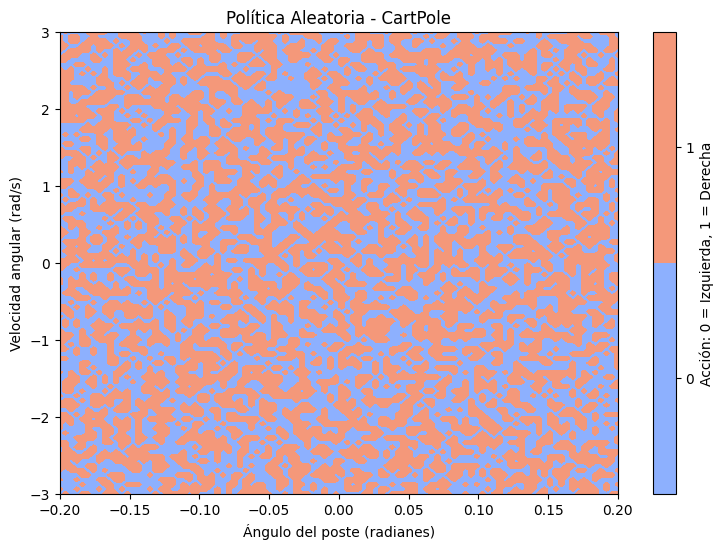

In [ ]:
# Crea una instancia del agente de Política Aleatoria.
# Se indica la cantidad de acciones disponibles en CartPole (2).
# Se establece la semilla 42 para reproducir la secuencia
# de decisiones aleatorias del agente.
agente_aleatorio = PoliticaAleatoria(env.action_space.n,seed=42)


# Ejecuta 1000 episodios con la política aleatoria.
# En cada episodio, el agente selecciona acciones al azar.
# No existe aprendizaje ni actualización de una estrategia.
# Se almacenan las recompensas totales obtenidas en cada episodio.
recompensas_aleatorio = agente_aleatorio.entrenar(
    env, episodios=1000, seed=42
)

# Evalúa el desempeño del agente durante 100 episodios.
# Se utiliza la semilla 42 como punto de partida para generar
# las mismas condiciones iniciales de evaluación que los otros agentes.
# Devuelve el promedio de recompensas y la lista de recompensas
# obtenidas en cada episodio.
promedio_aleatorio, recompensas_eval_aleatorio = agente_aleatorio.evaluar(
    env, episodios=100,seed=42
)

# Visualiza la política del agente aleatorio en el entorno CartPole.
# Recorre distintas combinaciones de ángulo y velocidad angular
# del péndulo, y muestra la acción seleccionada por el agente.
# Al ser una política aleatoria, las acciones no dependen del estado.
visualizar_politica_cartpole(
    agente_aleatorio,
    tipo="aleatoria",
    title="Política Aleatoria - CartPole"
)



##Visualización de la política aleatoria

Se generó un gráfico para representar las acciones seleccionadas por la política aleatoria en el entorno CartPole-v1.

En el eje horizontal se representa el ángulo del poste y en el eje vertical su velocidad angular. Los colores indican las dos acciones disponibles: mover el carrito hacia la izquierda (acción 0) o hacia la derecha (acción 1).

Se observa una distribución de colores sin un patrón definido, debido a que el agente selecciona sus acciones al azar, sin analizar el estado del entorno ni utilizar información aprendida.

Esta visualización permite observar la diferencia entre una política aleatoria y las políticas aprendidas mediante Q-Learning y DQN

En la evaluación de 100 episodios, obtuvo una recompensa promedio de 21,3 puntos, con un mejor resultado de 66 y un peor resultado de 8. Estos valores reflejan las limitaciones de una estrategia que no aprende ni adapta sus decisiones.

#Q-Learning

## ¿Qué adaptación necesitamos?
### En FrozenLake tenemo una tabla de 16 filas y 4 columnas:
- 16 filas: estados.
- 4 columnas: acciones.
### En CartPole tenemos:
- 4 observaciones continuas.
- 2 acciones posibles.
No podemos utilizar directamente los valores continuos como índices de una tabla. Para resolverlo, vamos a discretizar las cuatro observaciones, dividiéndolas en intervalos.

Por ejemplo, la posición del carrito puede agruparse en diferentes rangos, y lo mismo hacemos con la velocidad, el ángulo y la velocidad angular.

Así obtenemos una tabla Q que permite almacenar los valores de las dos acciones para cada combinación de intervalos.

In [ ]:
class QLearningCartPole:

     # Constructor: prepara e inicializa el agente Q-Learning.


    # Define la cantidad de intervalos para discretizar las observaciones, la tasa de aprendizaje, el factor de descuento y el valor inicial de epsilon, que controla la exploración.
    # También configura la reducción progresiva de epsilon, establece los límites de las cuatro observaciones del entorno CartPole y crea la tabla Q inicializada en cero.
    #Esta tabla tiene 20.000 valores, correspondientes a las combinaciones de los cuatro estados discretizados y las dos acciones posibles.
    # Por último, prepara las listas donde se almacenarán las recompensas y la evolución de epsilon durante el entrenamiento.
    def __init__(self, bins=10, lr=0.1, gamma=0.99, epsilon=1.0,seed=42):

        # bins	10	Divide cada observación en 10 intervalos.
        # lr	0.1	Determina cuánto se actualizan los valores Q.
        # gamma	0.99	Determina la importancia de las recompensas futuras.
        # epsilon	1.0	Comienza explorando el 100 % de las veces.
        # seed	42	Permite controlar la aleatoriedad.



        # Cantidad de intervalos utilizados para discretizar cada observación.
        self.bins = bins
        # Tasa de aprendizaje: determina cuánto se actualizan los valores de la tabla Q.
        self.lr = lr
        # Factor de descuento: determina la importancia de las recompensas futuras.
        self.gamma = gamma
        # Probabilidad inicial de explorar, es decir, seleccionar acciones aleatorias.
        self.epsilon = epsilon
        # Guarda la semilla utilizada para inicializar el agente.
        self.seed = seed

         # Crea un generador de números aleatorios propio del agente. Se utiliza para elegir acciones aleatorias durante la exploración.
        self.rng = np.random.default_rng(seed)

        # Factor por el cual se reduce epsilon después de cada episodio. Reduce la exploración un 0,5 % aproximadamente después de cada episodio.
        self.epsilon_decay = 0.995
        # Valor mínimo que puede alcanzar epsilon. Establece que la exploración nunca baje del 1 %.
        self.epsilon_min = 0.01
        # Esto permite que inicialmente el agente explore y, progresivamente, aproveche lo que aprendió.


        # Nombre del agente para identificarlo en los resultados.
        self.nombre = "Q-Learning Tabular CartPole"

        # Define los límites de discretización de las cuatro observaciones
        # del entorno CartPole: posición, velocidad, ángulo y velocidad angular.
        # Cada observación se divide en 10 intervalos.
        self.limites = [
            np.linspace(-2.4, 2.4, bins - 1),        # Posición del carrito
            np.linspace(-3.0, 3.0, bins - 1),        # Velocidad del carrito
            np.linspace(-0.2095, 0.2095, bins - 1),  # Ángulo del poste
            np.linspace(-3.5, 3.5, bins - 1)         # Velocidad angular del poste
        ]

        # Crea la tabla Q inicializada en cero.
        # Contiene 10 intervalos para cada una de las 4 observaciones
        # y 2 acciones posibles: izquierda y derecha.
        # Dimensiones: 10 x 10 x 10 x 10 x 2 = 20.000 valores.
        self.q_table = np.zeros((bins, bins, bins, bins, 2))

        # Lista para almacenar las recompensas obtenidas durante el entrenamiento.
        self.recompensas_entrenamiento = []

        # Lista para registrar la evolución de epsilon durante el entrenamiento.
        self.epsilons = []

    # --------------------------------------------------
    # Discretizar las observaciones continuas
    # --------------------------------------------------
    # Este método transforma las cuatro observaciones continuas de CartPole en valores discretos para que el agente Q-Learning pueda consultar la tabla Q.
    def discretizar_estado(self, estado):

        # Limita los valores de las observaciones a los rangos definidos.
        # Esto evita que valores extremos queden fuera de los intervalos.
        # Esto permite mantener los valores dentro de los rangos utilizados para la discretización.
        estado = np.clip(
            estado,
            [-2.4, -3.0, -0.2095, -3.5],
            [2.4, 3.0, 0.2095, 3.5]
        )

        # Convierte las cuatro observaciones continuas en índices discretos.
        # El método np.digitize() busca en cuál cae cada valor.
        # El resultado es una tupla con cuatro índices.

        estado_discreto = tuple(
            np.digitize(estado[i], self.limites[i])
            for i in range(4)
        )


        # Ejemplo
        # estado = [0.5, 1.2, 0.05, -0.8] Estado original (valores continuos)
        # Por ejemplo, para la posición del carrito, los límites se generan así: np.linspace(-2.4, 2.4, 9)  => -2.4, -1.8, -1.2, -0.6, 0, 0.6, 1.2, 1.8, 2.4
        # Como la posición es 0.5, pertenece al intervalo entre 0 y 0.6. np.digitize() devuelve el índice 5.
        # Se hace lo mismo con las otras tres observaciones
        # Discretización: cada valor se reemplaza por el índice de su intervalo. [5, 6, 5, 3]
        # El agente utiliza esa tupla para consultar la tabla Q: self.q_table[5, 6, 5, 3]
        # Allí encuentra dos valores:
        #- Valor Q para mover a la izquierda.
        #- Valor Q para mover a la derecha.
        # El agente puede elegir la acción que tenga el valor Q más alto.

        # Devuelve una tupla con los cuatro índices obtenidos. Esa tupla se utiliza para localizar el estado correspondiente dentro de a tabla Q.
        return estado_discreto

    # --------------------------------------------------
    # Seleccionar una acción utilizando Epsilon-Greedy
    # --------------------------------------------------
    # Este Metodo decide qué movimiento debe realizar el agente Q-Learning: mover el carrito hacia la izquierda o hacia la derecha.
    # Primero, discretiza el estado actual para poder consultar la tabla Q.
    # Luego utiliza la estrategia Epsilon-Greedy. Durante el entrenamiento, con una probabilidad determinada por epsilon,
    # selecciona una acción aleatoria para explorar.
    # Si no explora, elige la acción que tiene el mayor valor Q, aprovechando lo aprendido.
    def seleccionar_accion(self, estado, entrenando=True):
    #  Recibe:
    #- estado: las cuatro observaciones actuales de CartPole.
    #- entrenando=True: indica que el agente está entrenando y puede explorar.

      # Convierte el estado continuo recibido, en un estado discreto.
      estado = self.discretizar_estado(estado)

      # Durante el entrenamiento, utiliza epsilon-greedy:

      # Esta condición genera un número aleatorio entre 0 y 1 y lo compara con epsilon.
      #Por ejemplo, si epsilon = 0.8:
      #- Existe un 80 % de probabilidad de elegir una acción aleatoria.
      #- Existe un 20 % de probabilidad de elegir la acción aprendida.
      if entrenando and self.rng.random() < self.epsilon:
          #Si decide explorar, self.rng.integers(2) devuelve:
          # 0: mover a la izquierda. 1: mover a la derecha.
          return self.rng.integers(2)

      # Si no explora, selecciona la acción con mayor valor Q (explotación).
      return np.argmax(self.q_table[estado])

    # --------------------------------------------------
    # Actualizar los valores de la tabla Q
    # --------------------------------------------------

    # Este método se encarga de actualizar la tabla Q a partir de la experiencia del agente.
    # Primero, discretiza el estado actual y el siguiente estado para poder identificarlos dentro de la tabla.
    # Luego calcula el nuevo objetivo de aprendizaje.
    # Si el episodio terminó, considera únicamente la recompensa obtenida.
    # Si continúa, también tiene en cuenta la mejor recompensa futura estimada, utilizando el factor de descuento gamma.
    # Finalmente, actualiza el valor Q de la acción realizada, teniendo en cuenta el valor anterior, el nuevo objetivo y la tasa de aprendizaje.
    # De esta manera, el agente aprende progresivamente qué acciones son más convenientes para mantener el péndulo equilibrado.
    def actualizar_q(self, estado, accion, recompensa,
                     siguiente_estado, terminado):

        # Discretiza el estado actual y el siguiente estado.
        # Convierte el estado actual y el siguiente estado en índices discretos para poder consultar la tabla Q.
        # Por ejemplo:
        #- Estado actual: (5, 6, 5, 3).
        #- Siguiente estado: (5, 6, 6, 4)
        estado = self.discretizar_estado(estado)
        siguiente_estado = self.discretizar_estado(siguiente_estado)


        # Aquí el agente calcula cuánto debería valer la combinación de estado y acción que acaba de experimentar.
        if terminado:
            # Si el episodio terminó por una condición terminal, solamente considera la recompensa obtenida, porque no hay un siguiente estado del que obtener recompensas futuras.
            objetivo = recompensa
        else:
            # Si el episodio continúa, considera dos elementos:
            #- La recompensa que acaba de obtener.
            #- La mejor recompensa futura estimada para el siguiente estado, multiplicada por gamma.
            objetivo = recompensa + self.gamma * np.max(
                self.q_table[siguiente_estado]
            )

        # Actualiza el valor Q de la combinación estado-acción.
        # La actualización considera el valor anterior y el nuevo objetivo,
        # ponderado por la tasa de aprendizaje.
        self.q_table[estado][accion] += self.lr * (
            objetivo - self.q_table[estado][accion]
        )

    # --------------------------------------------------
    # Reducir epsilon progresivamente
    # --------------------------------------------------

    def decay_epsilon(self):

        # Reduce la probabilidad de exploración después de cada episodio.
        # epsilon no puede ser inferior al mínimo establecido.
        # Su objetivo es que el agente pase gradualmente de probar acciones al azar a utilizar las acciones que aprendió.
        self.epsilon = max(
            self.epsilon_min,
            self.epsilon * self.epsilon_decay
        )

    # --------------------------------------------------
    # Obtener la política aprendida
    # --------------------------------------------------

    def obtener_politica(self):

        # Este Metodo obtiene la política aprendida por el agente Q-Learning, es decir, determina qué acción conviene realizar para cada estado posible, según los valores almacenados en la tabla
        return np.argmax(self.q_table, axis=-1)

    # --------------------------------------------------
    # Entrenar el agente
    # --------------------------------------------------

    # Este método es el encargado de entrenar al agente Q-Learning durante 1000 episodios.
    # En cada episodio, primero reinicia el entorno y luego el agente selecciona una acción utilizando la estrategia Epsilon-Greedy.
    # La acción se ejecuta en CartPole, que devuelve el nuevo estado y la recompensa obtenida.
    # Con esa experiencia, el agente actualiza la tabla Q, acumula las recompensas y continúa tomando decisiones hasta que termina el episodio.
    # Al finalizar cada episodio, guarda los resultados y reduce progresivamente epsilon para disminuir la exploración.
    # Finalmente, cada 500 episodios muestra el promedio de las últimas 100 recompensas. Al completar el entrenamiento, devuelve todas las recompensas obtenidas.
    def entrenar(self, env, episodios=1000, seed=42):
        # Lista para almacenar la recompensa total de cada episodio.
        recompensas = []
        # Lista auxiliar para registrar las recompensas de los episodios.
        exitos_ventana = []

        print(f"Entrenando {self.nombre}...")

         # Ejecuta el proceso de aprendizaje 1000 veces. Cada repetición representa un episodio nuevo.
        for episodio in range(episodios):

            # Reinicia el entorno para comenzar un nuevo episodio.
            if episodio == 0:
                # Esto reinicia CartPole utilizando la semilla 42.
                estado, info = env.reset(seed=seed)
            else:
                # Reinicia CartPole, pero sin establecer una semilla nueva. El entorno continúa utilizando su generador aleatorio.
                estado, info = env.reset()

            # Indicadores que permiten controlar la finalización del episodio.
            terminado = False #indica si el episodio finalizó por una condición del entorno.
            truncado = False # indica si se alcanzó el límite de tiempo o pasos.
            # Inicializa el acumulador de recompensas del episodio.
            recompensa_total = 0

            # Ejecuta acciones hasta que el episodio termine o sea truncado.
            while not terminado and not truncado:

                # El agente decide si mueve el carrito hacia la izquierda o hacia la derecha utilizando la estrategia Epsilon-Greedy.
                # Puede explorar seleccionando una acción aleatoria o aprovechar lo que aprendió mediante la tabla Q.
                accion = self.seleccionar_accion(
                    estado, entrenando=True
                )

                # Ejecuta la acción en el entorno y obtiene:
                # siguiente estado, recompensa y condiciones de finalización
                # Siguiente_estado: nueva situación del carrito y el péndulo.
                # recompensa: puntos obtenidos (normalmente 1 por paso).
                # terminado: indica si finalizó por una condición terminal.
                # truncado: indica si alcanzó el límite de pasos.
                # Info: información adicional del entorno.
                siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)

                # Actualiza la tabla Q utilizando la experiencia obtenida.
                # Así el agente aprende qué acciones son más convenientes para cada estado.
                self.actualizar_q(
                    estado,
                    accion,
                    recompensa,
                    siguiente_estado,
                    terminado
                )

                # El siguiente estado pasa a ser el estado actual.
                estado = siguiente_estado
                # Acumula la recompensa obtenida en este paso.
                recompensa_total += recompensa

            # Guarda la recompensa total obtenida en el episodio.
            recompensas.append(recompensa_total)

            # Almacena también la recompensa en la lista auxiliar.
            exitos_ventana.append(recompensa_total)
            # Registra el valor actual de epsilon.
            self.epsilons.append(self.epsilon)

            # Reduce progresivamente epsilon para que el agente explore menos y aproveche más lo aprendido.
            self.decay_epsilon()

            # Cada 500 episodios calcula el promedio de las últimas 100 recompensas y muestra también el valor actual de epsilon.
            # Por ejemplo, al llegar al episodio 500 muestra el promedio de los episodios 401 al 500.
            if (episodio + 1) % 500 == 0:

                promedio = np.mean(recompensas[-100:])

                print(
                    f"Episodio {episodio + 1}: "
                    f"Promedio últimos 100 = {promedio:.2f}, "
                    f"Epsilon = {self.epsilon:.3f}"
                )
        # Guarda todas las recompensas obtenidas durante el entrenamiento.
        self.recompensas_entrenamiento = recompensas

        print("\nEntrenamiento finalizado.")
        # Devuelve la lista de recompensas por episodio.
        return recompensas

    # --------------------------------------------------
    # Evaluar el agente sin exploración
    # --------------------------------------------------

    # Este método permite evaluar el rendimiento del agente después del entrenamiento, ejecutando 100 episodios en el entorno CartPole.
    # En cada episodio reinicia el entorno utilizando una semilla diferente y el agente selecciona las acciones según los valores aprendidos en la tabla Q, sin realizar exploración aleatoria.
    # A medida que ejecuta las acciones, acumula las recompensas y contabiliza los pasos realizados hasta que finaliza cada episodio.
    # Una vez completados los 100 episodios, calcula la recompensa promedio, el promedio de pasos y el mejor resultado obtenido.
    # Finalmente, devuelve el promedio y la lista de recompensas para analizar el rendimiento del agente

    def evaluar(self, env, episodios=100, seed=42):

        print(f"Evaluando {self.nombre}...")

        # Listas para almacenar las recompensas y la cantidad de pasos
        # realizados en cada episodio.
        recompensas = []
        pasos_totales = []
        # Ejecuta la evaluación durante la cantidad de episodios indicada.
        for episodio in range(episodios):
            # Reinicia el entorno utilizando una semilla diferente por episodio. Esto permite utilizar condiciones iniciales reproducibles.
            estado, info = env.reset(seed=seed + episodio)

            terminado = False
            truncado = False
            # Inicializa los acumuladores del episodio.
            recompensa_total = 0
            pasos = 0

            # Ejecuta el agente hasta que finalice el episodio.
            while not terminado and not truncado:

                # Selecciona la mejor acción según la tabla Q.
                # entrenando=False desactiva la exploración aleatoria.
                accion = self.seleccionar_accion(
                    estado, entrenando=False
                )

                # Ejecuta la acción seleccionada en el entorno.
                estado, recompensa, terminado, truncado, info = env.step(accion)
                # Acumula la recompensa y contabiliza el paso realizado.
                recompensa_total += recompensa
                pasos += 1
             # Guarda los resultados del episodio evaluado.
            recompensas.append(recompensa_total)
            pasos_totales.append(pasos)
        # Calcula la recompensa promedio de todos los episodios evaluados.
        recompensa_promedio = np.mean(recompensas)


         # Muestra las métricas obtenidas durante la evaluación.
        print("\nResultados de evaluación:")
        print(f"Recompensa promedio: {recompensa_promedio:.2f}")
        print(f"Pasos promedio: {np.mean(pasos_totales):.2f}")
        print(f"Mejor resultado: {np.max(recompensas):.2f}")

        return recompensa_promedio, recompensas

In [ ]:
# --------------------------------------------------
# Crear y entrenar el agente Q-Learning
# --------------------------------------------------

# Crea una instancia del agente Q-Learning para el entorno CartPole.
agente_qlearning = QLearningCartPole(
    # Divide cada una de las cuatro observaciones del entorno
    # en 10 intervalos para convertir los estados continuos en discretos.
    bins=10,
    # Tasa de aprendizaje: determina cuánto se modifican los valores
    # de la tabla Q en cada actualización.
    lr=0.1,
    gamma=0.99, #  Factor de descuento: determina cuánto influyen las recompensas futuras en el aprendizaje.

    # Probabilidad inicial de exploración.
    # Comienza en 1.0 (100%), por lo que inicialmente selecciona
    # acciones aleatorias durante el entrenamiento.
    epsilon=1.0,
    # Semilla para inicializar el generador aleatorio del agente,
    # favoreciendo la reproducibilidad de los resultados.
    seed=42

)

# Entrena el agente durante 1000 episodios.
# En cada episodio, el agente interactúa con CartPole,
# selecciona acciones, recibe recompensas y actualiza la tabla Q.
# Durante el entrenamiento, epsilon disminuye progresivamente,
# reduciendo la exploración y favoreciendo las acciones aprendidas.
# Al finalizar, devuelve una lista con la recompensa total de cada episodio.
recompensas_qlearning = agente_qlearning.entrenar(
    env,
    episodios=1000,
    seed=42
)

Entrenando Q-Learning Tabular CartPole...
Episodio 500: Promedio últimos 100 = 69.69, Epsilon = 0.082
Episodio 1000: Promedio últimos 100 = 84.61, Epsilon = 0.010

Entrenamiento finalizado.


In [ ]:
# --------------------------------------------------
# Evaluar el agente Q-Learning
# --------------------------------------------------
# Evalúa el rendimiento del agente durante 100 episodios.
# En esta etapa no se actualiza la tabla Q ni se realiza
# exploración aleatoria. El agente utiliza la política aprendida.

# promedio_qlearning:
# Almacena la recompensa promedio obtenida en los 100 episodios.

# recompensas_eval_q:
# Almacena la recompensa total obtenida en cada episodio.
promedio_qlearning, recompensas_eval_q = agente_qlearning.evaluar(
    env,
    # Cantidad de episodios utilizados para evaluar el desempeño.
    episodios=100,
    # Semilla inicial para establecer las condiciones de evaluación.
    # Se utiliza la misma secuencia de semillas que para los otros agentes,
    # permitiendo realizar una comparación más consistente.
    seed=42
)

Evaluando Q-Learning Tabular CartPole...

Resultados de evaluación:
Recompensa promedio: 88.48
Pasos promedio: 88.48
Mejor resultado: 216.00


## Resultados del agente Q-Learning


Durante el entrenamiento de 1000 episodios, el agente Q-Learning mostró una mejora progresiva en su desempeño. El promedio de recompensas de los últimos 100 episodios pasó de 69,69 en el episodio 500 a 84,61 en el episodio 1000.

Por otra parte, el parámetro epsilon disminuyó de 0,082 a 0,010, reduciendo progresivamente la exploración y favoreciendo la utilización de las acciones aprendidas.

En la evaluación de 100 episodios, el agente obtuvo una recompensa promedio de 88,48 puntos, con un mejor resultado de 216 puntos.

Estos resultados muestran que el agente logró aprender una estrategia para mantener el péndulo equilibrado durante más tiempo. Sin embargo, todavía se encuentra lejos del máximo de 500 pasos establecido por el entorno CartPole-v1.

In [ ]:
# --------------------------------------------------
# Obtener la política aprendida por Q-Learning
# --------------------------------------------------

# Obtiene la política a partir de la tabla Q entrenada.
# Para cada estado discretizado, selecciona la acción
# que tiene el mayor valor Q.
#
# La política indica qué acción debe ejecutar el agente
# para cada combinación posible de las cuatro observaciones.

politica_qlearning = agente_qlearning.obtener_politica()
# Muestra las dimensiones de la política obtenida.
# Como se utilizan 10 intervalos para cada una de las
# cuatro observaciones, la política tiene dimensiones:
# 10 x 10 x 10 x 10.
#
# Cada posición representa un estado discretizado y contiene
# la acción recomendada: 0 (izquierda) o 1 (derecha).

print("Dimensiones de la política:", politica_qlearning.shape)

Dimensiones de la política: (10, 10, 10, 10)


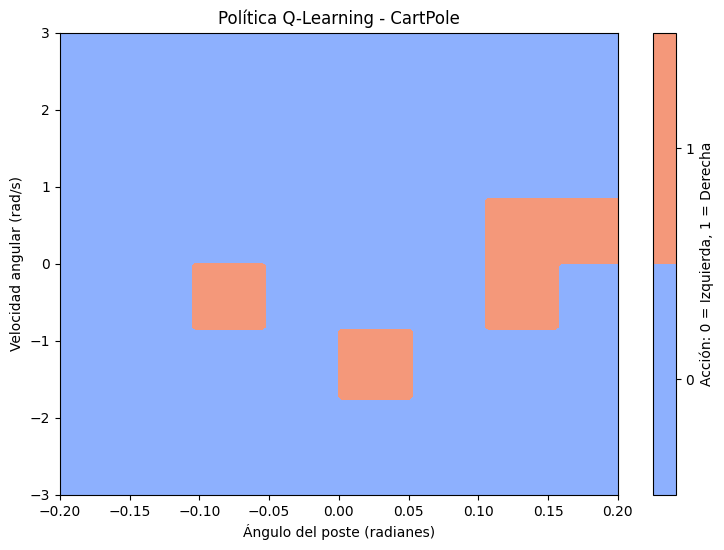

In [ ]:
# --------------------------------------------------
# Visualizar la política aprendida por Q-Learning
# --------------------------------------------------

# Genera un gráfico de la política que el agente aprendió
# durante el entrenamiento.
#
# Se utiliza el agente Q-Learning ya entrenado.
# El parámetro tipo="qlearning" indica que las acciones
# se seleccionan utilizando los valores almacenados en la tabla Q,
# sin realizar exploración aleatoria.
#
# El gráfico representa la acción recomendada para cada combinación de ángulo y velocidad angular del poste.
# La posición y velocidad del carrito se mantienen fijas en cero.
#
# Colores del gráfico:
# 0 = Mover el carrito hacia la izquierda.
# 1 = Mover el carrito hacia la derecha.

visualizar_politica_cartpole(
    agente_qlearning,
    tipo="qlearning",
    title="Política Q-Learning - CartPole"
)

## Visualización de la política Q-Learning

El gráfico representa la política aprendida por el agente Q-Learning en el entorno CartPole-v1.

En el eje horizontal se representa el ángulo del poste y en el eje vertical su velocidad angular. Los colores indican las acciones seleccionadas: azul para la acción 0 (izquierda) y naranja para la acción 1 (derecha).

Se observan regiones rectangulares debido a que Q-Learning utiliza intervalos discretizados. Cuando varios valores continuos pertenecen a un mismo intervalo, se consulta la misma posición de la tabla Q y se obtiene la misma acción.

Se observa un predominio de la acción izquierda en gran parte del gráfico, mientras que en determinadas regiones el agente selecciona la acción derecha. Este predominio también puede estar relacionado con estados cuyos valores Q todavía no fueron actualizados, ya que la tabla comienza inicializada en cero y, ante valores iguales, se selecciona la primera acción.

A diferencia de la política aleatoria, se observan regiones con decisiones determinadas por los valores almacenados en la tabla Q.

Esta representación permite visualizar cómo el agente utiliza lo aprendido durante el entrenamiento para seleccionar acciones según el estado del péndulo, manteniendo fijas en cero la posición y la velocidad del carrito.

# Deep Q-Network (DQN).
1. ¿Qué diferencia tiene con Q-Learning?
En Q-Learning utilizamos una tabla para almacenar los valores Q de cada estado y acción.

En DQN utilizamos una red neuronal que aprende a estimar esos valores.

En CartPole la red recibe cuatro datos:
1. Posición del carrito.
2. Velocidad del carrito.
3. Ángulo del poste.
4. Velocidad angular.
Y devuelve dos valores Q:
- Valor Q de mover hacia la izquierda.
- Valor Q de mover hacia la derecha.

In [ ]:
# --------------------------------------------------
# Crear la red neuronal del agente DQN
# --------------------------------------------------


# En esta parte definimos la arquitectura de la red neuronal que utilizará el agente DQN.
# La red recibe como entrada las cuatro observaciones del entorno CartPole: posición y velocidad del carrito, ángulo y velocidad angular del poste.
# Luego procesa esta información a través de dos capas ocultas de 128 neuronas cada una, utilizando la función de activación ReLU.
# Finalmente, la capa de salida genera dos valores Q estimados, uno para cada acción posible: mover el carrito hacia la izquierda o hacia la derecha.
# El método forward se encarga de pasar los datos por toda la red y devolver esos valores Q, que el agente utilizará para seleccionar sus acciones.

# Define una clase llamada RedDQN que hereda de nn.Module, la clase base de PyTorch para construir redes neuronales.
class RedDQN(nn.Module):
    # Constructor: define la arquitectura de la red neuronal.
    def __init__(self):
        # Inicializa la clase base de PyTorch (nn.Module).
        super().__init__()
        # nn.Sequential permite organizar las capas de la red neuronal en una secuencia. Los datos pasan por ellas en orden.
        self.red = nn.Sequential(
            # Capa de entrada:
            # Recibe las cuatro observaciones del entorno CartPole:
            # posición del carrito, velocidad del carrito,
            # ángulo del poste y velocidad angular.
            # Las transforma en 128 valores.

            # ¿Por qué se eligen 128 neuronas?
            # Es una decisión de diseño de la arquitectura de la red.
            # Se utilizan 128 neuronas para darle capacidad de aprender relaciones entre las cuatro observaciones y estimar qué acciones son más convenientes.

            nn.Linear(4, 128),
            # Función de activación ReLU.
            # Introduce no linealidad y permite aprender relaciones
            # más complejas entre las observaciones.
            nn.ReLU(),
            # Primera capa oculta:
            # Recibe los 128 valores anteriores y genera otros 128.
            nn.Linear(128, 128),

            # Aplica nuevamente la función de activación ReLU.
            nn.ReLU(),

            # Capa de salida:
            # Genera dos valores Q, uno por cada acción posible:
            # 0 = mover el carrito hacia la izquierda.
            # 1 = mover el carrito hacia la derecha.
            nn.Linear(128, 2)
        )
    # Define cómo se realiza el paso de los datos por la red neuronal.
    def forward(self, x):
        # Envía las observaciones de entrada a través de las capas de la red y devuelve los valores Q estimados para ambas acciones.
        return self.red(x)


In [ ]:
# --------------------------------------------------
# Crear la clase del agente DQN
# --------------------------------------------------


# Este constructor inicializa el agente DQN y configura todos los componentes necesarios para su aprendizaje.
# Primero, establece los parámetros principales, como la tasa de aprendizaje, el factor de descuento y la probabilidad inicial de exploración.
# Luego crea dos redes neuronales: una red principal, que aprende y estima los valores Q, y una red objetivo, que calcula los valores futuros utilizados como referencia durante el aprendizaje.
# También inicializa el optimizador Adam para actualizar los pesos de la red principal y la función de pérdida MSE para medir el error entre los valores estimados y los valores objetivo.
# Por último, crea una memoria de experiencias con capacidad para 10.000 registros y establece un lote de entrenamiento de 64 experiencias.
# De esta manera, deja preparado el agente para comenzar el entrenamiento mediante Deep Q-Network.

class AgenteDQN:
     # Constructor: inicializa los parámetros y componentes del agente.
    def __init__(self, lr=0.001, gamma=0.99, epsilon=1.0, seed=42):
         # Nombre del agente para identificarlo en los resultados.
        self.nombre = "Deep Q-Network CartPole"
        # Tasa de aprendizaje: controla cuánto se modifican los pesos
        # de la red neuronal durante cada actualización.
        self.lr = lr
        # Factor de descuento: determina la importancia de las recompensas futuras.
        #Ejemplo
        # Supongamos que tiene dos alternativas:
        #- Acción A: consigue 1 punto ahora, pero la barra se cae al siguiente paso.
        #- Acción B: consigue 1 punto ahora y logra mantener la barra equilibrada durante 5 pasos más.
        # ¿Qué significa para el modelo?
        # Con gamma = 0.99, el agente valora mucho las recompensas futuras. Por eso aprende que conviene elegir acciones que mantengan la barra equilibrada durante más tiempo.
        # En palabras simples: gamma determina cuánto le importa al agente lo que sucederá después de tomar una acción. Cuanto más cerca de 1, más importancia les da a las recompensas futuras.
        self.gamma = gamma
        # Probabilidad inicial de exploración.
        # Comienza en 1.0, lo que representa una exploración del 100%.
        self.epsilon = epsilon
        # Guarda la semilla utilizada para inicializar el agente.
        self.seed = seed

        # Crea un generador aleatorio propio del agente.
        # Se utiliza para seleccionar acciones aleatorias y muestras de experiencias.
        self.rng = random.Random(seed)

        # Establece la semilla de PyTorch para controlar la inicialización
        # aleatoria de los pesos de las redes neuronales.
        torch.manual_seed(seed)

        # Si hay una GPU disponible, establece también la semilla
        # para los generadores aleatorios de CUDA.
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        self.epsilon_decay = 0.995 # Factor por el cual se reduce epsilon después de cada episodio.
        self.epsilon_min = 0.01 # Valor mínimo que puede alcanzar epsilon.

        # Dispositivo utilizado para ejecutar la red neuronal:
        # CPU o GPU, según la configuración definida previamente.
        self.device = device

        # Crea la red neuronal principal.
        # Es la encargada de estimar los valores Q de las acciones.
        # Es la red que aprende y toma las decisiones.
        self.q_network = RedDQN().to(self.device)

        # Crea la red neuronal objetivo.
        # Se utiliza para calcular los valores Q futuros durante el aprendizaje.
        # Esta segunda red se utiliza para calcular los valores Q futuros que sirven como referencia para entrenar la red principal.
        # La red objetivo no se actualiza en cada paso del entrenamiento. Sus pesos se sincronizan cada 10 episodios.
        self.target_network = RedDQN().to(self.device)

        #¿Por qué se utilizan dos redes?
        # Porque separar las estimaciones actuales de los valores objetivo ayuda a estabilizar el aprendizaje.
        # Si se utilizara una sola red para calcular y actualizar constantemente ambos valores, las estimaciones podrían cambiar continuamente y dificultar el entrenamiento.


        # Copia los pesos iniciales de la red principal a la red objetivo.
        # De esta manera, ambas redes comienzan con los mismos parámetros.
        self.target_network.load_state_dict(
            self.q_network.state_dict()
        )

        # Define el optimizador Adam.
        # Se encarga de actualizar los pesos de la red principal
        # Utiliza la tasa de aprendizaje lr=0.001 para controlar las actualizaciones.
        # En otras palabras, ayuda a que la red ajuste sus parámetros para mejorar las estimaciones de los valores Q.
        self.optimizer = optim.Adam(
            self.q_network.parameters(),
            lr=self.lr
        )

        # Define la función de pérdida MSE.
        # Mide la diferencia entre los valores Q estimados  por la red y los valores objetivo calculados.
        # En DQN se utiliza nn.MSELoss() porque el problema consiste en aproximar valores numéricos (valores Q), no en clasificar categorías.

        #En DQN, la red neuronal no intenta clasificar si una acción es correcta o incorrecta. En DQN, la red neuronal aprende a responder: «¿Qué valor tiene realizar esta acción en este estado?».
        #Intenta estimar cuánto conviene realizar cada acción, según la recompensa futura que espera obtener.
        #En CartPole tenemos dos acciones posibles:
        #- Acción 0: mover el carro hacia la izquierda.
        #- Acción 1: mover el carro hacia la derecha.

        self.criterion = nn.MSELoss()

        # Crea la memoria de experiencias (Experience Replay).
        # Almacena hasta 10.000 experiencias del agente.
        # Cuando se llena, las experiencias más antiguas se reemplazan.

        #¿Para qué sirve?
        #Permite guardar experiencias del agente y utilizarlas posteriormente para entrenar la red neuronal, seleccionando muestras aleatorias en lugar de depender únicamente de la última interacción.
        self.memoria = deque(maxlen=10000)

        # Cantidad de experiencias que se seleccionan aleatoriamente
        # de la memoria para realizar cada actualización de la red.
        # Por ejemplo, en lugar de aprender utilizando una sola experiencia, el agente utiliza un conjunto de 64 experiencias.
        self.batch_size = 64

        # Lista para almacenar las recompensas obtenidas durante el entrenamiento.
        self.recompensas_entrenamiento = []

        # Lista para registrar la evolución de epsilon durante el entrenamiento.
        self.epsilons = []

    # ----------------------------------------
    # Seleccionar una acción
    # ----------------------------------------

      # Esta función permite que el agente DQN aprenda a decidir entre explorar acciones nuevas o aprovechar lo que ya aprendió mediante su red neuronal.
      # Para tomar esa decisión utiliza una estrategia llamada epsilon-greedy, que combina dos comportamientos:
      #- Exploración: probar acciones aleatorias para descubrir nuevas posibilidades.
      #- Explotación: elegir la acción que la red neuronal considera más conveniente según los valores Q estimados.
      # estado: contiene las 4 observaciones del entorno CartPole (posición y velocidad del carrito, ángulo y velocidad angular de la barra).
      # entrenando=True: indica que el agente está en etapa de entrenamiento y puede explorar.

    def seleccionar_accion(self, estado, entrenando=True):

      # Durante el entrenamiento, utiliza la estrategia epsilon-greedy.
      # Si un número aleatorio es menor que epsilon,
      # selecciona una acción aleatoria (exploración).
      if entrenando and self.rng.random() < self.epsilon:
          return self.rng.randrange(2)

      # Convierte el estado recibido en un tensor de PyTorch.
      # unsqueeze(0) agrega una dimensión para representar un lote  de una única observación.
      # Esta parte prepara los datos para que puedan ingresar a la red neuronal.
      estado_tensor = torch.FloatTensor(
          estado
      ).unsqueeze(0).to(self.device)

      # Desactiva el cálculo de gradientes porque aquí solamente
      # se necesita obtener una predicción de la red neuronal.
      with torch.no_grad():
          # La red principal calcula los valores Q estimados para las dos acciones posibles.
          valores_q = self.q_network(estado_tensor)

      # Selecciona la acción que tiene el mayor valor Q estimado.
      # item() convierte el resultado en un valor numérico de Python.
      return valores_q.argmax(dim=1).item()

    # ----------------------------------------
    # Guardar una experiencia en memoria
    # ----------------------------------------

    # Esta función de DQN se encarga de guardar las experiencias del agente en una memoria, para utilizarlas posteriormente durante el entrenamiento de la red neuronal.
    def guardar_experiencia(self, estado, accion, recompensa,
                            siguiente_estado, terminado):

       # Almacena una experiencia compuesta por:
        # estado actual, acción ejecutada, recompensa recibida,
        # siguiente estado y condición de finalización.
        # Esta información se utilizará posteriormente para entrenar la red.

        self.memoria.append((
            estado,
            accion,
            recompensa,
            siguiente_estado,
            terminado
        ))

    # ----------------------------------------
    # Entrenar la red neuronal
    # ----------------------------------------
    # Esta función es la que permite que DQN aprenda de sus experiencias. Compara lo que la red predice con lo que debería haber predicho y ajusta sus pesos para mejorar progresivamente la selección de acciones.
    # entrenar_red: analiza las experiencias y ajusta lo que aprendió para tomar mejores decisiones.
    def entrenar_red(self):

        # Comprueba si hay suficientes experiencias almacenadas
        # para formar un lote de entrenamiento.
        # Por lo tanto, si todavía no hay 64 experiencias almacenadas, no se realiza el entrenamiento.
        # ¿Por qué? Porque la red necesita un lote de experiencias para realizar una actualización.
        if len(self.memoria) < self.batch_size:
            return

        # Selecciona aleatoriamente 64 experiencias de la memoria.
        # Esto se conoce como Experience Replay o repetición de experiencias.
        # Permite que la red aprenda de situaciones anteriores y no solamente de las últimas acciones realizadas.
        lote = self.rng.sample(
            self.memoria,
            self.batch_size
        )
         # Separa las experiencias en sus cinco componentes.
          #Variable	        Qué representa
          # estados	        Situaciones iniciales.
          # acciones	      Acciones que realizó el agente.
          # recompensas	    Puntos que obtuvo.
          # siguientes	    Situaciones posteriores.
          # finales	        Indica si terminó el episodio.
        estados, acciones, recompensas, siguientes, finales = zip(*lote)

        # Convierte los estados actuales en un tensor de números decimales.
        # Esta conversión se realiza para que los datos puedan ser procesados por PyTorch y la red neuronal.
        estados = torch.FloatTensor(
            np.array(estados)
        ).to(self.device)


        # Convierte las acciones en un tensor de enteros, ya que representan índices de las acciones posibles.
        acciones = torch.LongTensor(
            acciones
        ).to(self.device)

        # Convierte las recompensas en un tensor de números decimales.
        recompensas = torch.FloatTensor(
            recompensas
        ).to(self.device)


        # Convierte los siguientes estados en un tensor.
        siguientes = torch.FloatTensor(
            np.array(siguientes)
        ).to(self.device)


        # Convierte los indicadores de finalización en un tensor.
        # El valor 1 indica que el episodio terminó realmente.
        # El valor 0 permite considerar las recompensas futuras.

        finales = torch.FloatTensor(
            finales
        ).to(self.device)

        # Calcula los valores Q actuales utilizando la red principal.
        # gather selecciona el valor Q correspondiente a la acción que realmente se ejecutó en cada estado.
        # El resultado es el valor Q que la red había estimado para la acción que efectivamente se realizó.
        q_actual = self.q_network(estados).gather(
            1, acciones.unsqueeze(1)
        ).squeeze(1)

        # Calcula los valores Q futuros utilizando la red objetivo.
        # no_grad evita calcular gradientes en esta parte del proceso.
        with torch.no_grad():
            # Obtiene el mayor valor Q estimado para cada siguiente estado.
            q_siguiente = self.target_network(
                siguientes
            ).max(1)[0]

            # Calcula el valor objetivo de Q-Learning:
            # recompensa actual + recompensa futura descontada.
            # Si el episodio terminó realmente, no se consideran
            # recompensas futuras porque finales vale 1.
            objetivo = recompensas + self.gamma * q_siguiente * (1 - finales)

        # Compara el valor Q que predijo la red principal con el objetivo calculado.
        perdida = self.criterion(q_actual, objetivo)

         # Limpia los gradientes acumulados de la actualización anterior
        self.optimizer.zero_grad()
        # Calcula cómo influyen los pesos de la red neuronal en el error obtenido, para determinar cómo deben modificarse.
        perdida.backward()

        # Limita la magnitud de los gradientes a un máximo de 10. Esto ayuda a evitar actualizaciones excesivamente grandes que podrían desestabilizar el entrenamiento.
        torch.nn.utils.clip_grad_norm_(
            self.q_network.parameters(), 10
        )

        # Finalmente, el optimizador Adam utiliza los gradientes calculados para modificar los pesos de la red neuronal principal.
        # Así, la red ajusta sus predicciones para acercarse a los valores objetivo.
        self.optimizer.step()

    # ----------------------------------------
    # Reducir epsilon
    # ----------------------------------------
    # Esta función se encarga de reducir progresivamente el valor de epsilon, es decir, disminuir la probabilidad de que el agente elija acciones aleatorias durante el entrenamiento.
    def decay_epsilon(self):

        # Reduce progresivamente la probabilidad de exploración.
        # epsilon se multiplica por el factor de decaimiento.
        # No puede ser inferior al valor mínimo establecido.
        self.epsilon = max(
            self.epsilon_min,
            self.epsilon * self.epsilon_decay
        )

    # ----------------------------------------
    # Entrenar el agente
    # ----------------------------------------

    # Esta función organiza el aprendizaje completo de DQN.
    # Coordina la interacción con el entorno, la memoria de experiencias, el entrenamiento de la red neuronal,
    # la reducción de exploración y la actualización de la red objetivo.
    # Entrenar: organiza las partidas, observa las jugadas y registra los resultados.

    def entrenar(self, env, episodios=1000, seed=42):
        # env: es el entorno CartPole.
        # episodios=1000: indica que el agente realizará hasta 1000 episodios de entrenamiento.
        # seed=42: establece una semilla para reproducir el inicio del entrenamiento.
        # recompensas: almacena la recompensa total obtenida en cada episodio.


        # Lista para almacenar la recompensa total de cada episodio.
        recompensas = []

        print(f"Entrenando {self.nombre}...")

        # Repite el proceso de aprendizaje durante la cantidad de episodios indicada.
        for episodio in range(episodios):

            # Antes de comenzar cada episodio, se reinicia CartPole.
            # - En el primer episodio se utiliza seed=42.
            # - En los siguientes episodios se reinicia sin especificar una nueva semilla.
            # Esto permite iniciar el entrenamiento con una semilla definida.
            if episodio == 0:
                estado, info = env.reset(seed=seed)
            else:
                estado, info = env.reset()

            # Indicadores para controlar la finalización del episodio.
            terminado = False # indica si el episodio finalizó por una condición del entorno.
            truncado = False # Indica si finalizó por un límite de tiempo o pasos.
            # Acumula los puntos obtenidos durante el episodio.
            recompensa_total = 0

            # Ejecuta acciones mientras el episodio no haya terminado.
            while not terminado and not truncado:

                # Selecciona una acción utilizando epsilon-greedy.
                # Explora: selecciona una acción aleatoria.
                # Explota: utiliza la red neuronal para elegir la acción con mayor valor Q.
                accion = self.seleccionar_accion(
                    estado, entrenando=True
                )

                # Envía la acción al entorno y recibe cinco resultados:
                #- siguiente_estado: nueva situación del carrito y la barra.
                #- recompensa: puntos obtenidos.
                #- terminado: indica si terminó el episodio.
                #- truncado: indica si se alcanzó el límite de pasos.
                #- info: información adicional del entorno.
                # Por ejemplo, si el agente mueve el carrito hacia la derecha, CartPole calcula cómo cambia la posición y el equilibrio de la barra.
                siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)


                # Guarda la experiencia obtenida en la memoria.
                # Guarda cinco elementos:
                #1. Estado actual.
                #2. Acción ejecutada.
                #3. Recompensa recibida.
                #4. Siguiente estado.
                #5. Si el episodio terminó.
                self.guardar_experiencia(
                    estado,
                    accion,
                    recompensa,
                    siguiente_estado,
                    float(terminado)
                )

                # Entrena la red neuronal utilizando un lote de experiencias seleccionadas aleatoriamente de la memoria.
                self.entrenar_red()

                # Actualiza el estado actual con el siguiente estado.
                estado = siguiente_estado
                # Acumula la recompensa obtenida en este paso.
                recompensa_total += recompensa

            # Reduce la probabilidad de exploración al finalizar el episodio.
            # Esto hace que progresivamente el agente explore menos y aproveche más lo aprendido por la red neuronal.
            self.decay_epsilon()

            # Cada 10 episodios copia los pesos de la red principal a la red objetivo para actualizar sus estimaciones.
            # Esta actualización periódica ayuda a estabilizar el aprendizaje.
            if (episodio + 1) % 10 == 0:
                self.target_network.load_state_dict(
                    self.q_network.state_dict()
                )
            # Guarda la recompensa total del episodio.
            recompensas.append(recompensa_total)

            # Registra el valor de epsilon después de reducirlo.
            self.epsilons.append(self.epsilon)


            # Cada 50 episodios muestra el promedio de las últimas 50 recompensas y el valor actual de epsilon.
            # Esto permite observar si el agente está mejorando a medida que avanza el entrenamiento.
            if (episodio + 1) % 50 == 0:
                promedio = np.mean(recompensas[-50:])
                print(
                    f"Episodio {episodio + 1}: "
                    f"Promedio últimos 50 = {promedio:.2f}, "
                    f"Epsilon = {self.epsilon:.3f}"
                )
        # Guarda todas las recompensas obtenidas durante el entrenamiento.
        self.recompensas_entrenamiento = recompensas

        print("\nEntrenamiento finalizado.")
        # Devuelve la lista de recompensas por episodio.
        return recompensas


    # entrenar() es la función que coordina el proceso completo de aprendizaje durante los episodios, mientras que
    # entrenar_red() es la encargada de actualizar los pesos de la red neuronal utilizando las experiencias almacenadas en memoria.

    # ----------------------------------------
    # Evaluar el agente sin exploración
    # ----------------------------------------
    # Esta funcion, permite comprobar qué tan bien aprendió el agente DQN, utilizando 100 episodios sin exploración aleatoria y calculando su rendimiento promedio, sus pasos promedio y su mejor resultado.
    def evaluar(self, env, episodios=100,seed=42):
        # env: entorno CartPole.
        # episodios=100: realiza 100 partidas de evaluación.
        # seed=42: semilla inicial para reproducir las condiciones.
        # recompensas: almacena los puntos obtenidos en cada episodio.
        # pasos_totales: registra cuántos pasos realizó en cada episodio.

        print(f"Evaluando {self.nombre}...")

        # Listas para almacenar las recompensas y los pasos
        # realizados en cada episodio.
        recompensas = []
        pasos_totales = []

        # Ejecuta la evaluación durante la cantidad de episodios indicada.
        for episodio in range(episodios):

            # Reinicia el entorno utilizando una semilla diferente para cada episodio.
            # Esto permite utilizar la misma secuencia de semillas al evaluar distintos agentes y facilitar la comparación.
            estado, info = env.reset(seed=seed + episodio)

            terminado = False # indica si el entorno finalizó.
            truncado = False # indica si se alcanzó el límite de tiempo.

            # Inicializa los acumuladores del episodio.
            recompensa_total = 0 # acumula los puntos.
            pasos = 0 # cuenta las acciones realizadas

            # Ejecuta acciones hasta que finalice el episodio.
            while not terminado and not truncado:
                # Selecciona la mejor acción según la red neuronal.
                # entrenando=False desactiva la exploración aleatoria. Por lo tanto, el agente utiliza la red neuronal para seleccionar la acción con mayor valor Q estimado.
                # Durante la evaluación no prueba acciones aleatorias: utiliza lo que aprendió.
                accion = self.seleccionar_accion(
                    estado, entrenando=False
                )
                # Ejecuta la acción y obtiene el nuevo estado y la recompensa.
                estado, recompensa, terminado, truncado, info = env.step(accion)
                # Acumula la recompensa y contabiliza los pasos realizados.
                recompensa_total += recompensa
                pasos += 1
            # Cuando termina cada episodio, almacena su recompensa total y la cantidad de pasos realizados. Al finalizar los 100 episodios, tendrá los resultados de todas las partidas.
            recompensas.append(recompensa_total)
            pasos_totales.append(pasos)
        # Calcula la recompensa promedio de todos los episodios.
        promedio = np.mean(recompensas)
        # Muestra las métricas de evaluación.
        print("\nResultados de evaluación:")
        print(f"Recompensa promedio: {promedio:.2f}")
        print(f"Pasos promedio: {np.mean(pasos_totales):.2f}")
        print(f"Mejor resultado: {np.max(recompensas):.2f}")
        # Devuelve el promedio y las recompensas individuales.
        return promedio, recompensas

    # ----------------------------------------
    # Obtener la acción recomendada por la red
    # ----------------------------------------

    def elegir_accion(self, estado, explorar=False):

        # Permite consultar que acción recomienda  la red neuronal para un estado determinado..
        # Por defecto, explorar=False, por lo que selecciona la acción con mayor valor Q estimado, sin exploración aleatoria.
        return self.seleccionar_accion(
            estado, entrenando=explorar
        )

In [ ]:
# --------------------------------------------------
# Crear el agente DQN
# --------------------------------------------------

# Este bloque se encarga de crear una instancia del agente DQN y configurar sus parámetros iniciales de aprendizaje.
agente_dqn = AgenteDQN(
    # Tasa de aprendizaje:
    # controla cuánto se actualizan los pesos de la red neuronal
    # durante el proceso de entrenamiento.
    lr=0.001,
    # Factor de descuento:
    # determina la importancia que tienen las recompensas futuras
    # en comparación con las recompensas inmediatas.
    gamma=0.99,
    # Probabilidad inicial de exploración:
    # comienza en 1.0 (100%), por lo que inicialmente el agente
    # selecciona acciones aleatorias durante el entrenamiento.
    # Este valor se reduce progresivamente mediante epsilon_decay.
    epsilon=1.0,
    # Semilla para controlar la inicialización aleatoria del agente,
    # incluyendo los generadores aleatorios y los pesos iniciales
    # de las redes neuronales.
    seed=42
)

In [ ]:
# --------------------------------------------------
# Entrenar el agente DQN
# --------------------------------------------------

# Ejecuta el entrenamiento del agente Deep Q-Network
# durante 1000 episodios en el entorno CartPole.
#
# Durante el entrenamiento, el agente:
# - Observa el estado del entorno.
# - Selecciona una acción mediante la estrategia epsilon-greedy.
# - Ejecuta la acción y recibe una recompensa.
# - Almacena la experiencia en la memoria (Experience Replay).
# - Selecciona experiencias aleatorias para entrenar la red neuronal.
# - Actualiza los pesos de la red principal.
# - Sincroniza la red objetivo cada 10 episodios.
# - Reduce progresivamente epsilon para disminuir la exploración.
#
# Al finalizar, devuelve una lista con las recompensas totales
# obtenidas en cada uno de los 1000 episodios.
recompensas_dqn = agente_dqn.entrenar(
    env,
    # Cantidad de episodios utilizados para entrenar el agente
    episodios=1000,
    # Semilla inicial para favorecer la reproducibilidad
    # de las condiciones iniciales del entrenamiento.
    seed=42
)

Entrenando Deep Q-Network CartPole...
Episodio 50: Promedio últimos 50 = 28.30, Epsilon = 0.778
Episodio 100: Promedio últimos 50 = 34.22, Epsilon = 0.606
Episodio 150: Promedio últimos 50 = 54.20, Epsilon = 0.471
Episodio 200: Promedio últimos 50 = 59.30, Epsilon = 0.367
Episodio 250: Promedio últimos 50 = 66.98, Epsilon = 0.286
Episodio 300: Promedio últimos 50 = 99.06, Epsilon = 0.222
Episodio 350: Promedio últimos 50 = 104.46, Epsilon = 0.173
Episodio 400: Promedio últimos 50 = 124.04, Epsilon = 0.135
Episodio 450: Promedio últimos 50 = 129.46, Epsilon = 0.105
Episodio 500: Promedio últimos 50 = 95.60, Epsilon = 0.082
Episodio 550: Promedio últimos 50 = 296.48, Epsilon = 0.063
Episodio 600: Promedio últimos 50 = 367.42, Epsilon = 0.049
Episodio 650: Promedio últimos 50 = 383.40, Epsilon = 0.038
Episodio 700: Promedio últimos 50 = 429.16, Epsilon = 0.030
Episodio 750: Promedio últimos 50 = 264.96, Epsilon = 0.023
Episodio 800: Promedio últimos 50 = 414.92, Epsilon = 0.018
Episodio 8

In [ ]:
# --------------------------------------------------
# Evaluar el agente DQN
# --------------------------------------------------

# Ejecuta la evaluación del agente durante 100 episodios.
# En esta etapa se utiliza la red neuronal ya entrenada,
# sin modificar sus pesos ni realizar nuevas actualizaciones.
#
# promedio_dqn:
# Almacena la recompensa promedio obtenida durante los 100 episodios.
#
# recompensas_eval_dqn:
# Almacena la recompensa total obtenida en cada episodio.
promedio_dqn, recompensas_eval_dqn = agente_dqn.evaluar(
    env,
    # Cantidad de episodios utilizados para evaluar el desempeño del agente.
    episodios=100,
    # Semilla inicial para establecer las condiciones de evaluación.
    # Se utiliza la misma secuencia de semillas que para los agentes
    # de Política Aleatoria y Q-Learning, facilitando la comparación.
    seed=42
)

Evaluando Deep Q-Network CartPole...

Resultados de evaluación:
Recompensa promedio: 183.50
Pasos promedio: 183.50
Mejor resultado: 266.00


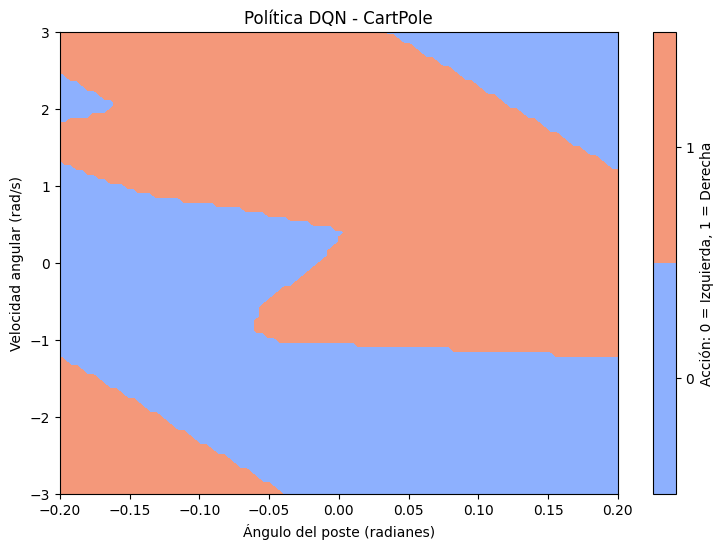

In [ ]:
# --------------------------------------------------
# Visualizar la política aprendida por DQN
# --------------------------------------------------

# Genera un gráfico de la política aprendida por el agente DQN
# durante los 1000 episodios de entrenamiento.
#
# Se utiliza la red neuronal principal para estimar los valores Q
# de las acciones posibles en cada estado.
#
# El parámetro tipo="dqn" indica que se utilizará el método
# elegir_accion() del agente, con explorar=False.
#
# El gráfico representa la acción recomendada para cada combinación
# de ángulo y velocidad angular del poste.
# La posición y velocidad del carrito se mantienen fijas en cero.
#
# Colores del gráfico:
# 0 = Mover el carrito hacia la izquierda.
# 1 = Mover el carrito hacia la derecha
visualizar_politica_cartpole(
    agente_dqn,
    tipo="dqn",
    title="Política DQN - CartPole"
)

# Por qué tiene esas formas?
A diferencia de Q-Learning, que utiliza una tabla con estados discretizados, DQN utiliza una red neuronal para estimar los valores Q.

La red aprende relaciones entre las observaciones y las acciones. Por eso, las regiones de colores pueden tener formas más curvas y transiciones graduales.

Por ejemplo:
- En algunas combinaciones de ángulo y velocidad angular predomina la acción izquierda.
- En otras combinaciones predomina la acción derecha.
Esto significa que DQN no toma siempre la misma decisión, sino que modifica su acción según el estado observado.

##  Comparación visual de los tres métodos

| Método | Característica del gráfico |
|---|---|
| **Política aleatoria** | Colores mezclados sin patrón definido. |
| **Q-Learning** | Regiones más definidas, según los intervalos discretizados. |
| **DQN** | Regiones con formas y transiciones determinadas por la red neuronal. |


## Visualización de la política DQN

El gráfico representa la política aprendida por el agente Deep Q-Network en el entorno CartPole-v1.

Se utilizan el ángulo del poste y su velocidad angular para representar las decisiones del agente. El color azul corresponde a la acción 0 (izquierda), mientras que el naranja representa la acción 1 (derecha).

A diferencia de Q-Learning tabular, DQN utiliza una red neuronal para estimar los valores Q de las acciones posibles. Esto permite trabajar directamente con las observaciones continuas del entorno, sin necesidad de discretizarlas.

Se observan diferentes regiones de decisión, donde la red neuronal selecciona una acción u otra según los valores de entrada.

Esta visualización permite analizar cómo el agente aprendió a tomar decisiones para intentar mantener el poste equilibrado.

#Adaptaciones realizadas respecto al notebook TP3 RL1

Para adaptar los algoritmos del notebook TP3 RL1 al entorno CartPole-v1 fue necesario realizar modificaciones debido a las diferencias entre ambos entornos.

1. Política aleatoria

Se mantuvo el funcionamiento original del algoritmo, adaptando la cantidad de acciones disponibles a las dos acciones de CartPole. Se utilizó como referencia para comparar el rendimiento de los agentes que realizan aprendizaje.

2. Q-Learning tabular

En FrozenLake los estados son discretos, mientras que CartPole presenta cuatro observaciones continuas. Por este motivo, se implementó una función de discretización mediante intervalos, utilizando 10 divisiones para cada variable.

Esto permitió construir una tabla Q de dimensiones 10 × 10 × 10 × 10 × 2, donde se almacenan los valores correspondientes a cada combinación de estados y acciones.

También se incorporó una estrategia Epsilon-Greedy para equilibrar la exploración y la explotación durante el entrenamiento.

3. Deep Q-Network (DQN)

Se adaptó la arquitectura de la red neuronal para trabajar con las características de CartPole.

La red recibe cuatro valores de entrada correspondientes a las observaciones del entorno y genera dos valores de salida, uno para cada acción posible.

Además, se implementaron Experience Replay y Target Network para mejorar la estabilidad del aprendizaje.

Se utilizó una red neuronal con dos capas ocultas de 128 neuronas cada una y activación ReLU.

### Criterios de implementación

Los tres agentes se ejecutaron durante 1000 episodios. En el caso de la política aleatoria, estos episodios se utilizaron como referencia de rendimiento, ya que no realiza un proceso de aprendizaje.

Posteriormente, los tres agentes fueron evaluados utilizando 100 episodios, registrando la recompensa promedio, el mejor resultado y el peor resultado.

Para favorecer la reproducibilidad de los experimentos, se estableció una semilla de 42 y se utilizaron las mismas condiciones iniciales durante la evaluación de los agentes.

De esta manera, se buscó mantener un criterio de comparación común, aunque los algoritmos presentan mecanismos de aprendizaje diferentes

# 2.4. Compare el desempeño de las políticas entrenadas en 2.3.

En este punto tenés que comparar cuál de los tres agentes se desempeñó mejor en CartPole-v1:
1. Política aleatoria.
2. Q-Learning tabular.
3. Deep Q-Network (DQN).
Para hacerlo, vamos a utilizar los resultados obtenidos en el punto 2.3.

La comparación se realizará mediante la recompensa promedio obtenida durante 100 episodios de evaluación. Recordá que CartPole entrega +1 por cada paso que el poste permanece equilibrado, con un máximo de 500 pasos por episodio.

In [ ]:
# Crear una tabla con los resultados de evaluación
resultados = pd.DataFrame({
    "Política": [
        "Aleatoria",
        "Q-Learning",
        "DQN"
    ],

    "Recompensa promedio": [
        promedio_aleatorio,
        promedio_qlearning,
        promedio_dqn
    ],

    "Mejor resultado": [
        np.max(recompensas_eval_aleatorio),
        np.max(recompensas_eval_q),
        np.max(recompensas_eval_dqn)
    ],

    "Peor resultado": [
        np.min(recompensas_eval_aleatorio),
        np.min(recompensas_eval_q),
        np.min(recompensas_eval_dqn)
    ]
})

display(resultados.round(2))

,Política,Recompensa promedio,Mejor resultado,Peor resultado
0,Aleatoria,21.30,66.0,8.0
1,Q-Learning,88.48,216.0,33.0
2,DQN,183.50,266.0,150.0


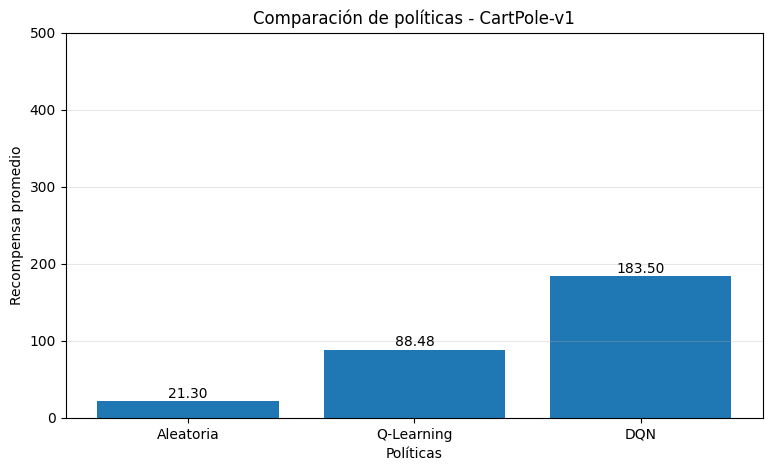

In [ ]:
#Graficar la comparación
nombres = ["Aleatoria", "Q-Learning", "DQN"]

promedios = [
    promedio_aleatorio,
    promedio_qlearning,
    promedio_dqn
]

plt.figure(figsize=(9, 5))

barras = plt.bar(nombres, promedios)

plt.title("Comparación de políticas - CartPole-v1")
plt.xlabel("Políticas")
plt.ylabel("Recompensa promedio")

plt.ylim(0, 500)

# Mostrar el valor encima de cada barra
for barra in barras:
    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 5,
        f"{altura:.2f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

#2.4. Comparación del desempeño de las políticas

Para comparar el desempeño de las tres políticas implementadas en el punto 2.3, se evaluó cada agente durante 100 episodios en el entorno CartPole-v1.

Se utilizaron tres métricas para realizar la comparación:
- Recompensa promedio: representa el desempeño general de la política.
- Mejor resultado: indica la mayor recompensa obtenida en un episodio.
- Peor resultado: indica la menor recompensa obtenida en un episodio.

Los resultados obtenidos fueron los siguientes:

| Política | Recompensa promedio | Mejor resultado | Peor resultado |
|:--------:|--------------------:|-----------------:|----------------:|
| Aleatoria | 21.30 | 66.0 | 8.0 |
| Q-Learning | 88.48 | 216.0 | 33.0 |
| DQN | 183.50 | 266.0 | 150.0 |

Análisis de los resultados
A partir de los resultados se pueden observar las siguientes diferencias:

- **Política aleatoria**: obtuvo una recompensa promedio de 21,30. Esto demuestra que seleccionar acciones al azar no permite mantener el poste en equilibrio durante mucho tiempo. Se utiliza como referencia para comparar los métodos de aprendizaje.

- **Q-Learning**: alcanzó una recompensa promedio de 88,48, superando considerablemente a la política aleatoria. Esto demuestra que el agente pudo aprender una estrategia para seleccionar acciones más convenientes mediante la tabla Q y la discretización de los estados.

- **DQN**: obtuvo el mejor resultado, con una recompensa promedio de 183,50 y un máximo de 266 pasos. Esto demuestra que, en esta experiencia, la red neuronal consiguió aprender una estrategia más efectiva que Q-Learning.

 **Comparación gráfica**
El siguiente gráfico permite visualizar las recompensas promedio obtenidas por cada política durante la evaluación.

### Conclusión de la comparación
De acuerdo con los resultados obtenidos, **DQN fue el método que presentó el mejor desempeño**, alcanzando una recompensa promedio de 183,50, frente a los 88,48 de Q-Learning y los 21,30 de la política aleatoria.

Q-Learning también logró mejorar considerablemente el desempeño respecto de la política aleatoria, demostrando que puede aprender una estrategia mediante la actualización de los valores de su tabla Q.

Por su parte, DQN consiguió mejores resultados al utilizar una red neuronal para aproximar los valores Q directamente a partir de las observaciones continuas del entorno, sin necesidad de discretizar los estados.



> En conclusión, para este experimento, DQN fue la estrategia más efectiva para resolver el entorno CartPole-v1, aunque todavía existe margen de mejora para alcanzar el máximo de 500 pasos.



# Comparación de recompensa promedio móvil
### Muestra cómo evoluciona el aprendizaje de Q-Learning y DQN durante los 1000 episodios.

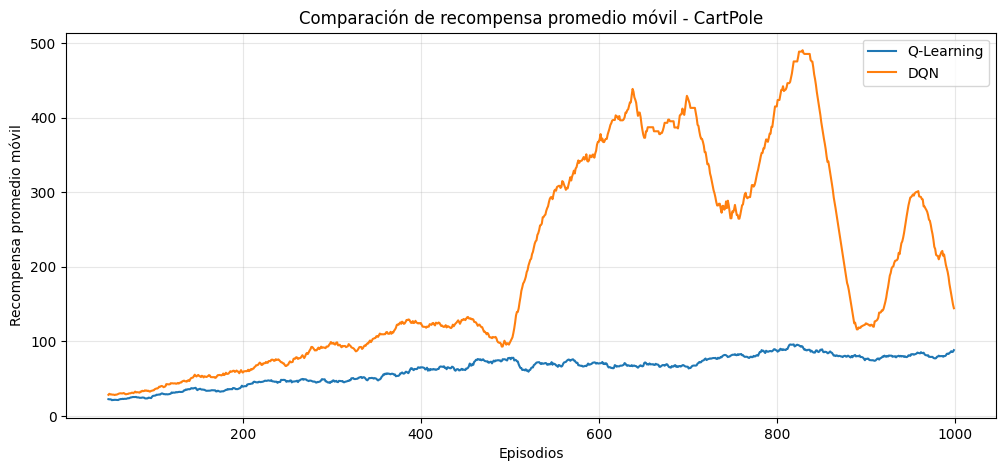

In [ ]:
# Ventana de promedio móvil
ventana = 50

promedio_q = pd.Series(
    agente_qlearning.recompensas_entrenamiento
).rolling(ventana).mean()

promedio_dqn = pd.Series(
    agente_dqn.recompensas_entrenamiento
).rolling(ventana).mean()

plt.figure(figsize=(12, 5))

plt.plot(promedio_q, label="Q-Learning")
plt.plot(promedio_dqn, label="DQN")

plt.title("Comparación de recompensa promedio móvil - CartPole")
plt.xlabel("Episodios")
plt.ylabel("Recompensa promedio móvil")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Interpretación del gráfico
En este gráfico comparamos la evolución del aprendizaje de Q-Learning y DQN mediante una recompensa promedio móvil de 50 episodios.

Podemos observar que Q-Learning presenta una mejora gradual, pero alcanza un rendimiento relativamente limitado, manteniéndose alrededor de los 80 a 90 puntos.

En cambio, DQN muestra una mejora significativa a partir de aproximadamente el episodio 500, llegando a alcanzar valores cercanos a los 490 puntos.

Si bien DQN presenta fluctuaciones importantes durante el entrenamiento, sus resultados son considerablemente superiores a los de Q-Learning.

Por lo tanto, podemos concluir que DQN logró un mejor desempeño en el entorno CartPole, consiguiendo mantener el equilibrio durante más tiempo. Pero las fluctuaciones  y la caída al final indican que todavía existe variabilidad en su rendimiento.


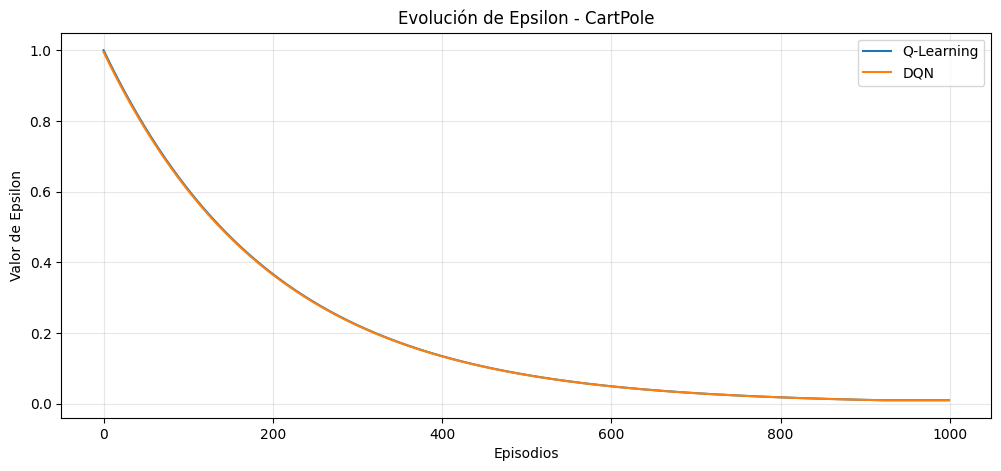

In [ ]:
### Evolución de Epsilon
plt.figure(figsize=(12, 5))

plt.plot(
    agente_qlearning.epsilons,
    label="Q-Learning"
)

plt.plot(
    agente_dqn.epsilons,
    label="DQN"
)

plt.title("Evolución de Epsilon - CartPole")
plt.xlabel("Episodios")
plt.ylabel("Valor de Epsilon")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Conclusion

En este gráfico podemos observar la evolución de Epsilon durante los 1000 episodios de entrenamiento.

Epsilon comienza en 1, lo que significa que inicialmente los agentes priorizan la exploración, probando diferentes acciones para conocer el entorno.

A medida que avanza el entrenamiento, Epsilon disminuye progresivamente hasta alcanzar un valor mínimo de 0.01. Esto permite que los agentes reduzcan la exploración y aprovechen cada vez más los conocimientos adquiridos.

Observamos que Q-Learning y DQN presentan curvas prácticamente iguales, debido a que utilizan una estrategia de reducción de Epsilon similar.

De esta manera, ambos algoritmos comienzan explorando y progresivamente pasan a priorizar la explotación.

# 2.5. Conclusiones, experiencia, dificultades y fuentes
## Conclusiones
A través de este trabajo se pudo experimentar con diferentes métodos de aprendizaje por refuerzo, implementando tres estrategias para resolver el entorno CartPole-v1: una política aleatoria, Q-Learning tabular y Deep Q-Network (DQN).

Los resultados obtenidos permitieron observar diferencias importantes entre los métodos. La política aleatoria presentó el menor desempeño, con una recompensa promedio de 21,30. Q-Learning logró mejorar este resultado, alcanzando un promedio de 88,48. Por último, DQN obtuvo el mejor desempeño, con una recompensa promedio de 183,50.

Esto permitió comprobar que los métodos de aprendizaje por refuerzo pueden aprender a tomar decisiones a partir de la interacción con el entorno, mejorando su desempeño respecto de una estrategia que selecciona acciones al azar.

También se pudo observar que Q-Learning necesita discretizar las observaciones continuas para trabajar con una tabla de valores Q, mientras que DQN utiliza una red neuronal para aproximar esos valores directamente a partir de las observaciones del entorno.

En conclusión, para el entorno, los parámetros y las condiciones de entrenamiento utilizados en este experimento, DQN presentó los mejores resultados.

## Experiencia con el trabajo
La realización de este trabajo permitió comprender de manera práctica cómo funciona el aprendizaje por refuerzo y cómo un agente puede aprender a tomar decisiones mediante la interacción con un entorno.

Fue interesante observar las diferencias entre los métodos implementados y comprobar cómo los resultados mejoran cuando el agente aprende a partir de sus experiencias.

Además, permitió relacionar conceptos teóricos como estados, acciones, recompensas, políticas, exploración y explotación con una implementación concreta utilizando Python, Gymnasium y PyTorch.

## Dificultades encontradas
La realización de este trabajo permitió comprender de manera práctica cómo funciona el aprendizaje por refuerzo y cómo un agente puede aprender a tomar decisiones mediante la interacción con un entorno.

Fue interesante observar las diferencias entre los métodos implementados y comprobar cómo los resultados mejoran cuando el agente aprende a partir de sus experiencias.

Además, permitió relacionar conceptos teóricos como estados, acciones, recompensas, políticas, exploración y explotación con una implementación concreta utilizando Python, Gymnasium y PyTorch.

## Dificultades encontradas

Una de las principales dificultades fue adaptar los métodos de aprendizaje al entorno CartPole-v1, ya que sus observaciones son continuas y no discretas.

En el caso de Q-Learning, fue necesario discretizar las variables del entorno para poder representarlas mediante una tabla Q.

Otra dificultad fue comprender e implementar DQN, especialmente el uso de la red neuronal, la memoria de experiencias (Experience Replay) y la red objetivo (Target Network).

También fue necesario realizar pruebas y ajustar parámetros como la tasa de aprendizaje, el factor de descuento y el valor de exploración (epsilon) para obtener resultados satisfactorios.

Por último, fue importante implementar una evaluación común para los tres agentes, utilizando la misma cantidad de episodios y las mismas condiciones iniciales, para favorecer una comparación consistente

## Fuentes y referencias utilizadas
Para realizar el trabajo se consultó la documentación oficial de las herramientas utilizadas y los materiales de referencia de la asignatura.

1. Gymnasium: documentación oficial del entorno CartPole-v1.
https://gymnasium.farama.org/environments/classic_control/cart_pole/

2. PyTorch: documentación oficial para la implementación de redes neuronales.
https://pytorch.org/docs/stable/index.html

3. PyTorch Tutorials: tutoriales y ejemplos de aprendizaje profundo.
https://pytorch.org/tutorials/

4. Material de la asignatura: notebook TP3 RL1, utilizado como referencia para el desarrollo de las implementaciones.